Uploading the dataset

In [ ]:
!pip install -q kagglehub

import kagglehub
import pandas as pd
import os
import glob

path = kagglehub.dataset_download(
    "balaka18/email-spam-classification-dataset-csv"
)

print("Path to dataset files:", path)

csv_files = glob.glob(os.path.join(path, "*.csv"))

print("CSV files found:", csv_files)

if not csv_files:
    raise FileNotFoundError("No CSV file was found in the downloaded dataset.")

df = pd.read_csv(csv_files[0], header = 0)

display(df.head())


Using Colab cache for faster access to the 'email-spam-classification-dataset-csv' dataset.
Path to dataset files: /kaggle/input/email-spam-classification-dataset-csv
CSV files found: ['/kaggle/input/email-spam-classification-dataset-csv/emails.csv']


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


Exploring the Dataset

In [ ]:
print("Dataset Shape: ", df.shape)

print("First 10 column names: ")
print(df.columns[:10].tolist())

print("last 10 column names: ")
print(df.columns[-10:].tolist())

print("Data Types: ")
print(df.dtypes.value_counts())

print("Missing values: ", df.isnull().sum().sum())

print("Duplicate rows: ", df.duplicated().sum())


Dataset Shape:  (5172, 3002)
First 10 column names: 
['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou']
last 10 column names: 
['connevey', 'jay', 'valued', 'lay', 'infrastructure', 'military', 'allowing', 'ff', 'dry', 'Prediction']
Data Types: 
int64     3001
object       1
Name: count, dtype: int64
Missing values:  0
Duplicate rows:  0


In [ ]:
#Spam = 1
#Not Spam = 0
x = df.drop(columns=["Email No.", "Prediction"])
y = df["Prediction"]

print("Feature Shape: ", x.shape)
print("Target Shape: ", y.shape)

print("Target distribution: ")
print(y.value_counts())

print("Target percentages: ")
print((y.value_counts(normalize=True) * 100).round(2))

Feature Shape:  (5172, 3000)
Target Shape:  (5172,)
Target distribution: 
Prediction
0    3672
1    1500
Name: count, dtype: int64
Target percentages: 
Prediction
0    71.0
1    29.0
Name: proportion, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)


Logistic Regression

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

cv = StratifiedKFold(
    n_splits = 5,
    shuffle = True,
    random_state = 42
)

cv_accuracy = cross_val_score(
    model,
    x_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

cv_f1 = cross_val_score(
    model,
    x_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Accuracy for each fold:", cv_accuracy)
print("Mean CV accuracy:", cv_accuracy.mean())
print("Mean CV F1-score:", cv_f1.mean())


Accuracy for each fold: [0.96497585 0.97705314 0.96130593 0.97702539 0.96251511]
Mean CV accuracy: 0.9685750836794421
Mean CV F1-score: 0.9470699480852731


Final Test Accuracy:  0.966183574879227
Test Precision:  0.9206349206349206
Test Recall:  0.9666666666666667
Test F1_score: 0.943089430894309
Classification report:                precision    recall  f1-score   support

           0       0.99      0.97      0.98       735
           1       0.92      0.97      0.94       300

    accuracy                           0.97      1035
   macro avg       0.95      0.97      0.96      1035
weighted avg       0.97      0.97      0.97      1035



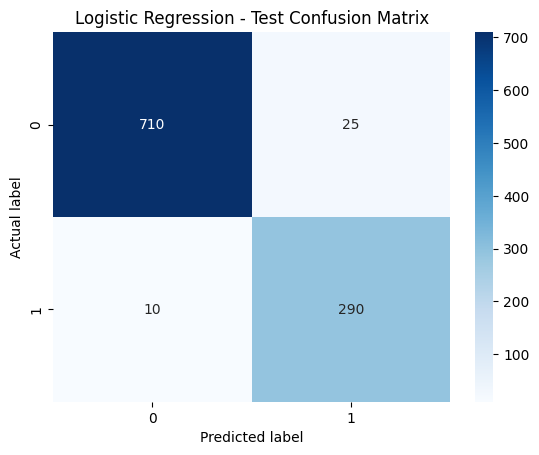

In [ ]:
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import seaborn as sns
import matplotlib.pyplot as plt

model.fit(x_train, y_train)

y_test_pred = model.predict(x_test)

print("Final Test Accuracy: ", accuracy_score(y_test, y_test_pred))

print("Test Precision: ", precision_score(y_test, y_test_pred, zero_division=0))

print("Test Recall: ", recall_score(y_test, y_test_pred, zero_division=0))

print("Test F1_score:", f1_score(y_test, y_test_pred, zero_division=0))

print("Classification report: ", classification_report(y_test, y_test_pred, zero_division=0))

cm = confusion_matrix(y_test, y_test_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Logistic Regression - Test Confusion Matrix")
plt.show()




Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
dt_model = DecisionTreeClassifier(
    max_depth = 20,
    min_samples_leaf=2,
    random_state=42
)

cv_f1 = cross_val_score(
    dt_model,
    x_train,
    y_train,
    cv=cv,
    scoring="f1"
)

cv_accuracy = cross_val_score(
    dt_model,
    x_train,
    y_train,
    cv=cv,
    scoring = "accuracy"
)

print("Accuracy for each fold:", cv_accuracy)
print("Mean CV accuracy:", cv_accuracy.mean())
print("Mean CV F1-score:", cv_f1.mean())

Accuracy for each fold: [0.9263285  0.9178744  0.92019347 0.92623942 0.91777509]
Mean CV accuracy: 0.9216821758407374
Mean CV F1-score: 0.8662015697286943


Descision Tree
Test Accuracy:  0.9159420289855073
Test Precision: 0.8561872909698997
Test Recall: 0.8533333333333334
Test F1-score: 0.8547579298831386
Classification Report: 
              precision    recall  f1-score   support

           0       0.94      0.94      0.94       735
           1       0.86      0.85      0.85       300

    accuracy                           0.92      1035
   macro avg       0.90      0.90      0.90      1035
weighted avg       0.92      0.92      0.92      1035



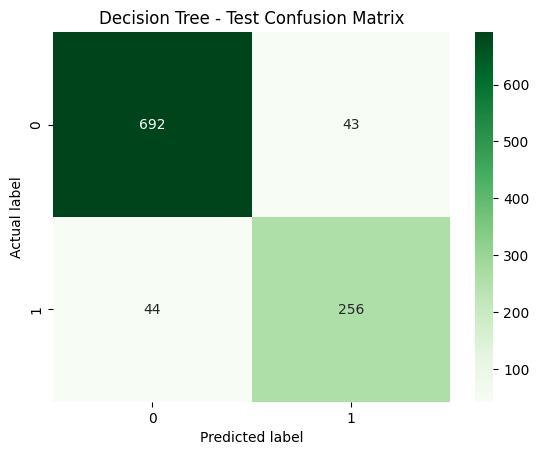

In [ ]:
dt_model.fit(x_train, y_train)

y_test_pred_dt = dt_model.predict(x_test)

print("Descision Tree")
print("Test Accuracy: ", accuracy_score(y_test, y_test_pred_dt))
print("Test Precision:", precision_score(y_test, y_test_pred_dt, zero_division=0))
print("Test Recall:",recall_score(y_test, y_test_pred_dt, zero_division=0))
print("Test F1-score:",f1_score(y_test, y_test_pred_dt, zero_division=0))

print("Classification Report: ")
print(classification_report(y_test,y_test_pred_dt, zero_division=0))

cm_dt = confusion_matrix(y_test, y_test_pred_dt)

sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Greens")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Decision Tree - Test Confusion Matrix")
plt.show()




In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

cv_accuracy = cross_val_score(
    knn_model,
    x_train,
    y_train,
    cv=cv,
    scoring = "accuracy"
)

cv_f1 = cross_val_score(
    knn_model,
    x_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Accuracy for each fold:", cv_accuracy)
print("Mean CV accuracy:", cv_accuracy.mean())
print("Mean CV F1-score:", cv_f1.mean())

Accuracy for each fold: [0.82004831 0.80193237 0.81257557 0.82345828 0.80532044]
Mean CV accuracy: 0.8126669937904888
Mean CV F1-score: 0.7453533701114115


KNN Model

KNN
Test Accuracy: 0.8338164251207729
Test Precision: 0.6434977578475336
Test Recall: 0.9566666666666667
Test F1-score: 0.7694369973190348

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.78      0.87       735
           1       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035



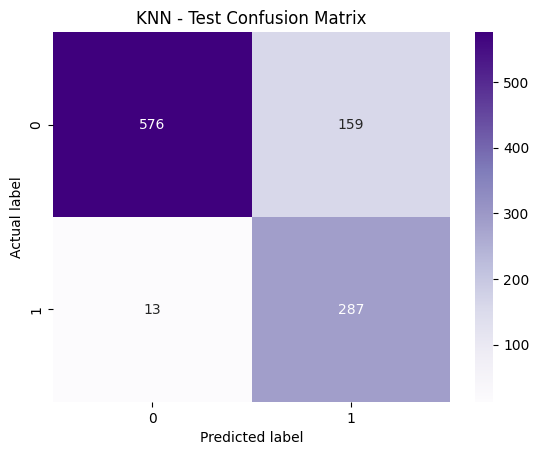

In [ ]:
knn_model.fit(x_train,y_train)
y_test_pred_knn = knn_model.predict(x_test)

print("KNN")
print("Test Accuracy:", accuracy_score(y_test, y_test_pred_knn))
print("Test Precision:", precision_score(y_test, y_test_pred_knn, zero_division=0))
print("Test Recall:", recall_score(y_test, y_test_pred_knn, zero_division=0))
print("Test F1-score:", f1_score(y_test, y_test_pred_knn, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test, y_test_pred_knn, zero_division=0
))


cm_knn = confusion_matrix(y_test, y_test_pred_knn)

sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Purples")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("KNN - Test Confusion Matrix")
plt.show()

SVM Model

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

svm_model = make_pipeline(
    StandardScaler(),
    LinearSVC(C=1.0, max_iter=20000, random_state=42)
)

cv_accuracy = cross_val_score(
    svm_model,
    x_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

cv_f1 = cross_val_score(
    svm_model,
    x_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Accuracy for each fold:", cv_accuracy)
print("Mean CV accuracy:", cv_accuracy.mean())
print("Mean CV F1-score:", cv_f1.mean())


Accuracy for each fold: [0.93357488 0.93719807 0.91898428 0.94679565 0.91293833]
Mean CV accuracy: 0.9298982411253058
Mean CV F1-score: 0.889335671220997


SVM
Test Accuracy: 0.9342995169082126
Test Precision: 0.8391812865497076
Test Recall: 0.9566666666666667
Test F1-score: 0.8940809968847352

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.93      0.95       735
           1       0.84      0.96      0.89       300

    accuracy                           0.93      1035
   macro avg       0.91      0.94      0.92      1035
weighted avg       0.94      0.93      0.94      1035



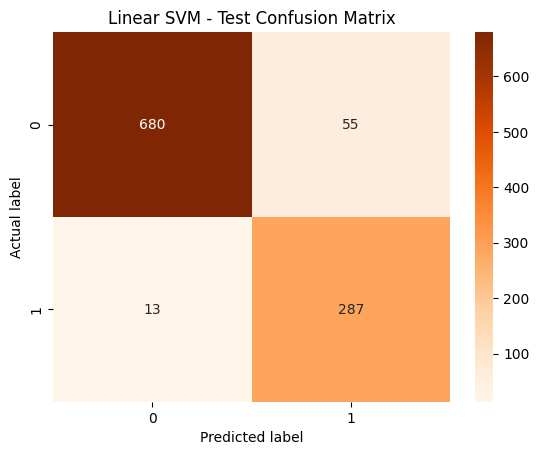

In [ ]:
svm_model.fit(x_train, y_train)

y_test_pred_svm = svm_model.predict(x_test)

print("SVM")
print("Test Accuracy:", accuracy_score(y_test, y_test_pred_svm))
print("Test Precision:", precision_score(y_test, y_test_pred_svm, zero_division=0))
print("Test Recall:", recall_score(y_test, y_test_pred_svm, zero_division=0))
print("Test F1-score:",f1_score(y_test, y_test_pred_svm, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test, y_test_pred_svm, zero_division=0
))

cm_svm = confusion_matrix(y_test, y_test_pred_svm)

sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Oranges")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Linear SVM - Test Confusion Matrix")
plt.show()

Random Forest Model

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

cv_accuracy = cross_val_score(
    rf_model,
    x_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

cv_f1 = cross_val_score(
    rf_model,
    x_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Accuracy for each fold:", cv_accuracy)
print("Mean CV accuracy:", cv_accuracy.mean())
print("Mean CV F1-score:", cv_f1.mean())


Accuracy for each fold: [0.96859903 0.96014493 0.96493349 0.97339782 0.96735187]
Mean CV accuracy: 0.9668854307227684
Mean CV F1-score: 0.9425051660746648


Test Accuracy: 0.9623188405797102
Test Precision: 0.9335548172757475
Test Recall: 0.9366666666666666
Test F1-score: 0.9351081530782029
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       735
           1       0.93      0.94      0.94       300

    accuracy                           0.96      1035
   macro avg       0.95      0.95      0.95      1035
weighted avg       0.96      0.96      0.96      1035



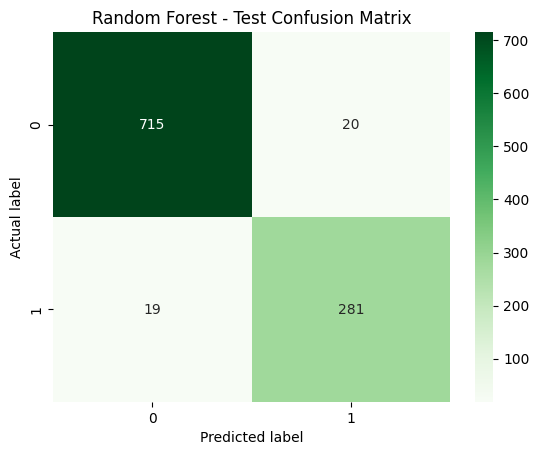

In [ ]:
rf_model.fit(x_train, y_train)
y_test_pred_rf = rf_model.predict(x_test)

print("Test Accuracy:", accuracy_score(y_test, y_test_pred_rf))
print("Test Precision:", precision_score(y_test, y_test_pred_rf, zero_division=0))
print("Test Recall:", recall_score(y_test, y_test_pred_rf, zero_division=0))
print("Test F1-score:", f1_score(y_test, y_test_pred_rf, zero_division=0))

print("Classification Report:")
print(classification_report(y_test, y_test_pred_rf, zero_division=0))

cm_rf = confusion_matrix(y_test, y_test_pred_rf)

sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Greens")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Random Forest - Test Confusion Matrix")
plt.show()

## **Model Comparison**

The table below compares the performance of five machine learning models
on the held-out test set.

| Model | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| Logistic Regression | 96.62% | 92.06% | 96.67% | 94.31% |
| Decision Tree | 91.59% | 85.62% | 85.33% | 85.48% |
| KNN | 83.38% | 64.35% | 95.67% | 76.94% |
| Linear SVM | 93.43% | 83.92% | 95.67% | 89.41% |
| Random Forest | 96.23% | 93.36% | 93.67% | 93.51% |